# Peak SWE and peak streamflow

Spearman rank correlation between **water-year peak observed SWE** and **water-year peak observed streamflow** at Ross.

SWE is Yukon snow-survey snow water equivalent (`mm`) from `data/yukon_snow_data.csv`. Each `location_code` is a station, and the observation time is `sample_date`. The file already includes the Twin Creeks composite (`09BA-SC02`) as its own record, separate from Twin Creeks A (`09BA-SC02A`) and Twin Creeks B (`09BA-SC02B`).

Set `STATION_ID` to the station to assess. It may be a `location_code` or a `location_name`. Only that station is paired with streamflow and scored.

Streamflow is daily discharge (`m3 s-1`) at Ross River at Ross River (WSC `09BA001`) from `data/ross_daily_discharge.csv`.

The water year starts on **1 October**, so the snow-season SWE maximum is paired with the melt-season streamflow maximum that follows it. A water year enters the correlation only when:

- SWE has at least one finite observation in March–May (the sample reaches the usual peak season; a year that ends in December is excluded),
- streamflow has at least one finite observation in May–July (the freshet was observed).

The peak itself is the maximum finite value over the whole water year, not only inside that window. For the snow surveys, that maximum is the largest survey of the year, not a continuous seasonal maximum.

In [10]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

from snowda.io.streamflow import read_streamflow_observations
from snowda.obs_qm import water_year

%matplotlib inline

SWE_CSV = Path("/Users/dcasson/GitHub/snowda/data/yukon_snow_data.csv")
FLOW_CSV = Path("/Users/dcasson/GitHub/snowda/data/ross_daily_discharge.csv")

WY_START_MONTH = 10
SWE_SEASON_MONTHS = (3, 4, 5)
FLOW_SEASON_MONTHS = (5, 6, 7)
MIN_YEARS = 3

# Station used for the correlation (location_code or location_name).
# Ross basin (09BA):
#   09BA-SC01   Ross River Hill Snow Course
#   09BA-SC02   Twin Creeks Snow Course (composite)
#   09BA-SC02A  Twin Creeks A Snow Course
#   09BA-SC02B  Twin Creeks B Snow Course
#   09BA-SC03   Hoole River Snow Course
#   09BA-SC04   Burns Lake Snow Course
#   09BA-SC05   Finlayson Airstrip Snow Course
STATION_ID = "09BA-SC02"

## Water-year peaks

`STATION_ID` is paired with the gauge. Overlapping water years are the sample for Spearman’s ρ. The catalog lists every station so the id or name can be changed and the notebook re-run.

In [11]:
def _finite_frame(times, values, value_name: str) -> pd.DataFrame:
    index = pd.DatetimeIndex(times)
    frame = pd.DataFrame(
        {
            "time": index,
            "water_year": water_year(index, start_month=WY_START_MONTH),
            value_name: np.asarray(values, dtype=float),
        }
    )
    return frame[np.isfinite(frame[value_name])].copy()


def water_year_peaks(frame: pd.DataFrame, value_name: str, season_months) -> pd.DataFrame:
    """Maximum in each water year that has an observation inside ``season_months``."""
    rows = []
    for year, group in frame.groupby("water_year"):
        in_season = group["time"].dt.month.isin(season_months)
        if not bool(in_season.any()):
            continue
        idx = group[value_name].idxmax()
        rows.append(
            {
                "water_year": int(year),
                f"peak_{value_name}": float(group.loc[idx, value_name]),
                f"peak_{value_name}_date": pd.Timestamp(group.loc[idx, "time"]),
                f"n_{value_name}": int(len(group)),
            }
        )
    return pd.DataFrame(rows)


def read_yukon_swe(path: Path) -> pd.DataFrame:
    """Snow-water-equivalent surveys, one row per station and sample date."""
    with path.open() as handle:
        skip = next(
            i for i, line in enumerate(handle) if line.startswith("location_code,")
        )
    raw = pd.read_csv(path, skiprows=skip)
    swe = raw.loc[
        raw["parameter"].eq("snow water equivalent"),
        ["location_code", "location_name", "units", "sample_date", "result"],
    ].copy()
    if not swe["units"].eq("mm").all():
        raise ValueError(
            f"Expected SWE in mm, found {sorted(swe['units'].dropna().unique())}"
        )
    swe["sample_date"] = pd.to_datetime(swe["sample_date"], errors="coerce")
    swe["result"] = pd.to_numeric(swe["result"], errors="coerce")
    swe = swe.dropna(subset=["sample_date", "result"])
    return swe.rename(
        columns={
            "location_code": "station_id",
            "location_name": "station_name",
            "sample_date": "time",
            "result": "swe",
        }
    ).drop(columns="units")


swe = read_yukon_swe(SWE_CSV)
flow = read_streamflow_observations(FLOW_CSV)
flow_peaks = water_year_peaks(
    _finite_frame(flow.time.values, flow.values, "q"),
    "q",
    FLOW_SEASON_MONTHS,
)

paired_parts = []
for (sid, name), group in swe.groupby(["station_id", "station_name"], sort=False):
    swe_peaks = water_year_peaks(
        _finite_frame(group["time"].to_numpy(), group["swe"].to_numpy(), "swe"),
        "swe",
        SWE_SEASON_MONTHS,
    )
    merged = swe_peaks.merge(flow_peaks, on="water_year", how="inner")
    if merged.empty:
        continue
    merged.insert(0, "station_id", str(sid))
    merged.insert(1, "station_name", str(name))
    paired_parts.append(merged)

paired_all = pd.concat(paired_parts, ignore_index=True)

catalog = (
    paired_all.groupby(["station_id", "station_name"], sort=False)
    .size()
    .rename("n_years")
    .reset_index()
)
match = (catalog["station_id"] == STATION_ID) | (catalog["station_name"] == STATION_ID)
if int(match.sum()) != 1:
    choices = catalog.to_string(index=False)
    raise ValueError(
        f"STATION_ID {STATION_ID!r} does not match one station. "
        f"Choose a station_id or station_name from:\n{choices}"
    )
chosen_id = str(catalog.loc[match, "station_id"].iloc[0])
paired = paired_all.loc[paired_all["station_id"] == chosen_id].reset_index(drop=True)
print(
    f"Selected {paired['station_name'].iloc[0]} ({chosen_id}), "
    f"{len(paired)} water years"
)
catalog

Selected Twin Creeks Snow Course (composite) (09BA-SC02), 48 water years


,station_id,station_name,n_years
0,08AA-SC01,Canyon Lake Snow Course,48
1,08AA-SC02,Alder Creek Snow Course,45
2,08AA-SC03,Aishihik Lake Snow Course,31
3,08AA-SC04,Haines Junction Farm Snow Course,25
4,08AB-SC01,Felsite Creek Snow Course,8
...,...,...,...
85,10EA-SC01,Tungsten Snow Course,11
86,10HA-SC01,Tsichu River Snow Course,7
87,10MA-SC01,Blackstone River Snow Course,49
88,10MA-SC02,Ogilvie River Snow Course,49


## Spearman correlation

ρ is computed on the paired water years for the selected station. Fewer than three overlapping years are plotted but not assigned a coefficient.

In [12]:
def _spearman(group: pd.DataFrame) -> tuple[float, float]:
    if len(group) < MIN_YEARS:
        return np.nan, np.nan
    result = spearmanr(group["peak_swe"], group["peak_q"])
    return float(result.statistic), float(result.pvalue)


summary_rows = []
for sid, group in paired.groupby("station_id", sort=False):
    rho, p_value = _spearman(group)
    summary_rows.append(
        {
            "station_id": sid,
            "station_name": group["station_name"].iloc[0],
            "n_years": int(len(group)),
            "first_water_year": int(group["water_year"].min()),
            "last_water_year": int(group["water_year"].max()),
            "spearman_rho": rho,
            "p_value": p_value,
        }
    )
summary = pd.DataFrame(summary_rows)

for row in summary.itertuples(index=False):
    if np.isfinite(row.spearman_rho):
        print(
            f"{row.station_name} ({row.station_id}): "
            f"Spearman ρ = {row.spearman_rho:.3f} "
            f"(n = {row.n_years}, p = {row.p_value:.3g})"
        )
    else:
        print(
            f"{row.station_name} ({row.station_id}): "
            f"n = {row.n_years} overlapping water years; "
            f"Spearman not computed (need at least {MIN_YEARS})."
        )

summary

Twin Creeks Snow Course (composite) (09BA-SC02): Spearman ρ = 0.725 (n = 48, p = 5.76e-09)


,station_id,station_name,n_years,first_water_year,last_water_year,spearman_rho,p_value
0,09BA-SC02,Twin Creeks Snow Course (composite),48,1977,2024,0.724684,5.763176e-09


/var/folders/46/6y3tkg051374dmsgd2w6l9gw0000gn/T/ipykernel_18918/2022688312.py:47: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc="upper left", framealpha=0.9)


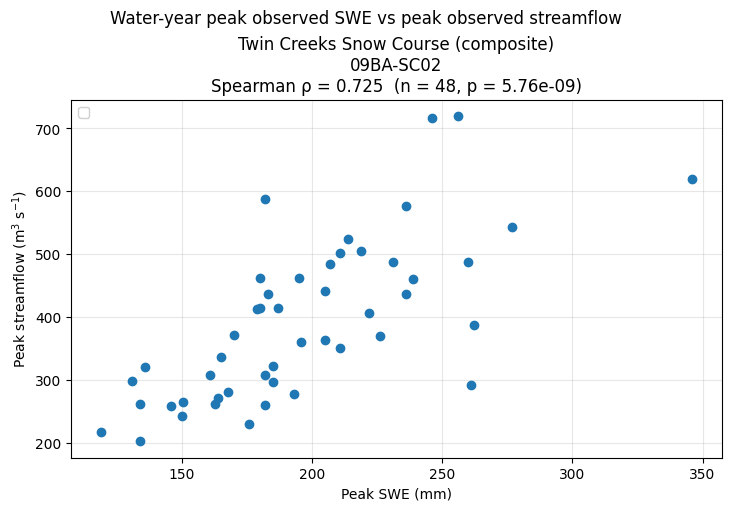

In [13]:
station_ids = list(summary["station_id"])
n_sta = len(station_ids)
fig, axes = plt.subplots(
    1,
    n_sta,
    figsize=(7.2 if n_sta == 1 else 4.6 * n_sta, 5.0),
    sharey=False,
    squeeze=False,
    layout="constrained",
)
axes = axes[0]

for ax, sid in zip(axes, station_ids):
    group = paired.loc[paired["station_id"] == sid]
    row = summary.loc[summary["station_id"] == sid].iloc[0]
    ax.scatter(group["peak_swe"], group["peak_q"], s=36, color="C0", zorder=3)
    if len(group) <= 12:
        for sample in group.itertuples(index=False):
            ax.annotate(
                str(int(sample.water_year)),
                (sample.peak_swe, sample.peak_q),
                textcoords="offset points",
                xytext=(4, 4),
                fontsize=8,
                color="0.35",
            )
    if np.isfinite(row["spearman_rho"]):
        stats = (
            f"Spearman ρ = {row['spearman_rho']:.3f}  "
            f"(n = {int(row['n_years'])}, p = {row['p_value']:.3g})"
        )
    else:
        stats = f"n = {int(row['n_years'])} (need ≥ {MIN_YEARS} years)"
    ax.set_title(f"{row['station_name']}\n{sid}\n{stats}")
    if len(group) <= 12:
        ymin, ymax = ax.get_ylim()
        ax.set_ylim(ymin, ymax + 0.12 * (ymax - ymin))
    ax.set_xlabel(r"Peak SWE (mm)")
    ax.grid(True, alpha=0.3)
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()
    lo = max(xmin, ymin)
    hi = min(xmax, ymax)
    if hi > lo:
        ax.set_xlim(xmin, xmax)
        ax.set_ylim(ymin, ymax)
        ax.legend(loc="upper left", framealpha=0.9)

axes[0].set_ylabel(r"Peak streamflow (m$^3$ s$^{-1}$)")
fig.suptitle("Water-year peak observed SWE vs peak observed streamflow")
plt.show()

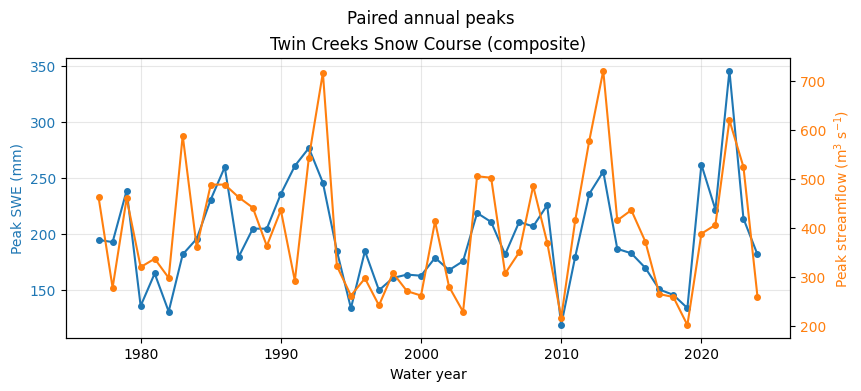

In [14]:
fig, axes = plt.subplots(
    n_sta,
    1,
    figsize=(8.5, 3.8 if n_sta == 1 else 2.8 * n_sta),
    squeeze=False,
    layout="constrained",
)
axes = axes[:, 0]

for ax, sid in zip(axes, station_ids):
    group = paired.loc[paired["station_id"] == sid].sort_values("water_year")
    name = group["station_name"].iloc[0]
    ax.plot(
        group["water_year"],
        group["peak_swe"],
        color="C0",
        marker="o",
        ms=4,
        label="Peak SWE",
    )
    ax.set_ylabel(r"Peak SWE (mm)", color="C0")
    ax.tick_params(axis="y", labelcolor="C0")
    ax2 = ax.twinx()
    ax2.plot(
        group["water_year"],
        group["peak_q"],
        color="C1",
        marker="o",
        ms=4,
        label="Peak streamflow",
    )
    ax2.set_ylabel(r"Peak streamflow (m$^3$ s$^{-1}$)", color="C1")
    ax2.tick_params(axis="y", labelcolor="C1")
    if len(group) <= 12:
        years = group["water_year"].astype(int).tolist()
        ax.set_xticks(years)
    ax.set_title(name)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Water year")
fig.suptitle("Paired annual peaks")
plt.show()

## Paired water years

`n_swe` is the number of finite SWE observations in that water year. Survey peaks are the largest of those surveys.

In [15]:
table = paired.copy()
table["peak_swe_date"] = pd.to_datetime(table["peak_swe_date"]).dt.strftime("%Y-%m-%d")
table["peak_q_date"] = pd.to_datetime(table["peak_q_date"]).dt.strftime("%Y-%m-%d")
table = table.sort_values(["station_name", "water_year"]).reset_index(drop=True)
table

,station_id,station_name,water_year,peak_swe,peak_swe_date,n_swe,peak_q,peak_q_date,n_q
0,09BA-SC02,Twin Creeks Snow Course (composite),1977,195.0,1977-03-30,5,462.0,1977-05-28,365
1,09BA-SC02,Twin Creeks Snow Course (composite),1978,193.0,1978-03-31,5,278.0,1978-06-06,365
2,09BA-SC02,Twin Creeks Snow Course (composite),1979,239.0,1979-04-03,4,460.0,1979-06-06,365
3,09BA-SC02,Twin Creeks Snow Course (composite),1980,136.0,1980-04-30,5,320.0,1980-05-17,366
4,09BA-SC02,Twin Creeks Snow Course (composite),1981,165.0,1981-03-31,5,337.0,1981-05-24,365
5,09BA-SC02,Twin Creeks Snow Course (composite),1982,131.0,1982-03-29,5,298.0,1982-06-03,365
6,09BA-SC02,Twin Creeks Snow Course (composite),1983,182.0,1983-03-31,4,588.0,1983-06-04,365
7,09BA-SC02,Twin Creeks Snow Course (composite),1984,196.0,1984-04-29,5,360.0,1984-06-11,366
8,09BA-SC02,Twin Creeks Snow Course (composite),1985,231.0,1985-04-29,5,488.0,1985-06-07,365
9,09BA-SC02,Twin Creeks Snow Course (composite),1986,260.0,1986-04-29,4,488.0,1986-06-02,365
